In [18]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

BASE_DIR = Path(
    r"D:\1-Kuliah\SEKRIPSI\Skripsi_Traffic_Density_Estimation_and_Forecasting"
)

DATA_DIR = BASE_DIR / "06_Forecasting" / "percobaan-bi-lstm"

# Mapping nama percobaan dengan nama foldernya
EXPERIMENTS = {
    "Percobaan 1": DATA_DIR / "output_bilstm_percobaan-1" / "evaluation_normalized.csv",
    "Percobaan 2": DATA_DIR / "output_bilstm_percobaan-2" / "evaluation_normalized.csv",
    "Percobaan 3": DATA_DIR / "output_bilstm_percobaan-3" / "evaluation_normalized.csv",
    "Percobaan 4": DATA_DIR / "output_bilstm_percobaan-4" / "evaluation_normalized.csv",
    "Percobaan 5": DATA_DIR / "output_bilstm_percobaan-5" / "evaluation_normalized.csv",
}

MODEL_NAMES = {
    "Percobaan 1": "Bi-LSTM 32-16",
    "Percobaan 2": "Bi-LSTM 64-16",
    "Percobaan 3": "Residual Bi-LSTM 8",
    "Percobaan 4": "Residual Bi-LSTM 16",
    "Percobaan 5": "Residual Bi-LSTM 24",
}


In [19]:
# membaca file evaluasi
df_list = []

for exp_name, file_path in EXPERIMENTS.items():
    temp_df = pd.read_csv(file_path, index_col=0)
    temp_df.index.name = "Arah"
    temp_df = temp_df.reset_index()
    temp_df.insert(0, "Percobaan", exp_name)
    df_list.append(temp_df)

comparison_df = pd.concat(df_list, ignore_index=True)

In [20]:
display(
    comparison_df.style.format({
        "NMAE (%)": "{:.2f}",
        "NRMSE (%)": "{:.2f}"
    })
)

,Percobaan,Arah,NMAE (%),NRMSE (%)
0,Percobaan 1,DS_IN,16.07,19.78
1,Percobaan 1,DS_OUT,8.61,10.65
2,Percobaan 2,DS_IN,12.93,15.96
3,Percobaan 2,DS_OUT,6.87,8.88
4,Percobaan 3,DS_IN,6.89,8.32
5,Percobaan 3,DS_OUT,6.64,9.59
6,Percobaan 4,DS_IN,6.51,8.04
7,Percobaan 4,DS_OUT,6.17,8.68
8,Percobaan 5,DS_IN,6.06,7.55
9,Percobaan 5,DS_OUT,6.97,9.71


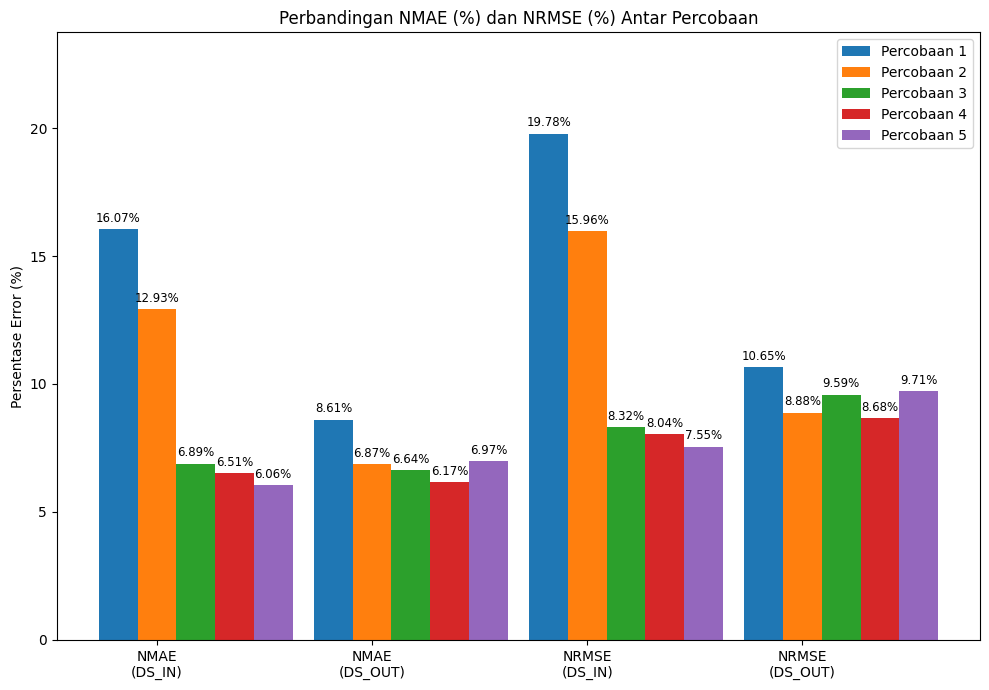

In [46]:
# visualisasi perbandingan
fig, ax = plt.subplots(figsize=(10, 7))

categories = [
    ("NMAE (%)", "DS_IN"),
    ("NMAE (%)", "DS_OUT"),
    ("NRMSE (%)", "DS_IN"),
    ("NRMSE (%)", "DS_OUT"),
]
labels = ["NMAE\n(DS_IN)", "NMAE\n(DS_OUT)", "NRMSE\n(DS_IN)", "NRMSE\n(DS_OUT)"]

percobaan_list = comparison_df["Percobaan"].unique()
x = np.arange(len(categories))
width = 0.18

for i, percobaan in enumerate(percobaan_list):
    subset = comparison_df[comparison_df["Percobaan"] == percobaan]
    values = [
        subset[subset["Arah"] == arah][metric].values[0]
        for metric, arah in categories
    ]
    
    offset = (i - 1) * width
    bars = ax.bar(x + offset, values, width, label=percobaan)
    ax.bar_label(bars, fmt="%.2f%%", padding=3, fontsize=8.5)

ax.set_title("Perbandingan NMAE (%) dan NRMSE (%) Antar Percobaan")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Persentase Error (%)")
ax.set_ylim(0, comparison_df[["NMAE (%)", "NRMSE (%)"]].max().max() * 1.2)
ax.legend()

plt.tight_layout()
plt.show()